# Homework 2

Done by: Vladyslav Danylyshyn and Iia Maharyta (team: Miguel)

In [1]:
import numpy as np
import pandas as pd
import cv2
import yaml
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import check_random_state

## Data Understanding

In [2]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle").strip()

In [3]:
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p data
!unzip -q -o data/*.zip -d data

100% 9.88G/9.88G [02:18<00:00, 76.8MB/s]



In [4]:
ROOT = Path("data")


def class_names(split):
    meta = yaml.safe_load((ROOT / split / "data.yaml").read_text())
    names = meta["names"]
    if isinstance(names, dict):
        return {int(k): v for k, v in names.items()}
    return dict(enumerate(names))


def load_split(split):
    split_dir = ROOT / split
    rows = []
    for seq_dir in sorted((split_dir / "images").iterdir()):
        if not seq_dir.is_dir():
            continue
        seq = seq_dir.name
        for img_path in sorted(seq_dir.glob("*.jpg")):
            stem = img_path.stem
            label_path = split_dir / "labels" / seq / f"{stem}.txt"
            ignore_path = split_dir / "ignore" / seq / f"{stem}.txt"
            pairs = [("object", label_path), ("ignore", ignore_path)]
            any_box = False
            for kind, txt_path in pairs:
                if not txt_path.exists():
                    continue

                for line in txt_path.read_text().splitlines():
                    vals = line.split()
                    if len(vals) < 4:
                        continue

                    if len(vals) == 4:
                        cls_id, cx, cy, bw, bh = None, *map(float, vals)

                    else:
                        cls_id = int(float(vals[0]))
                        cx, cy, bw, bh = map(float, vals[1:5])

                    rows.append({
                        "split": split,
                        "sequence": seq,
                        "frame": stem,
                        "image_path": str(img_path),
                        "kind": kind,
                        "class_id": cls_id,
                        "cx": cx, "cy": cy, "w": bw, "h": bh,
                    })
                    any_box = True

            if not any_box:
                rows.append({
                    "split": split,
                    "sequence": seq,
                    "frame": stem,
                    "image_path": str(img_path),
                    "kind": "empty",
                    "class_id": None,
                    "cx": None, "cy": None, "w": None, "h": None,
                })

    return pd.DataFrame(rows)


names = class_names("train")
train_df = load_split("train")
val_df = load_split("val")

test_df = pd.read_csv(ROOT / "test_images.csv")
test_df["image_path"] = test_df["file_name"].map(lambda p: str(ROOT / p))

print("classes:", names)
print("train", train_df["sequence"].nunique(), "videos,", train_df["image_path"].nunique(), "frames,", len(train_df), "rows")
print("val  ", val_df["sequence"].nunique(), "videos,", val_df["image_path"].nunique(), "frames,", len(val_df), "rows")
print("test ", test_df["clip"].nunique(), "videos,", len(test_df), "frames")
train_df.head()

classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'van', 4: 'truck', 5: 'tricycle', 6: 'bus', 7: 'motor'}
train 56 videos, 24201 frames, 1169362 rows
val   7 videos, 2846 frames, 118127 rows
test  48 videos, 3811 frames


,split,sequence,frame,image_path,kind,class_id,cx,cy,w,h
0,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,0.0,0.328497,0.776455,0.026042,0.116402
1,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,0.0,0.322917,0.757275,0.026786,0.112434
2,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,5.0,0.427455,0.923280,0.064732,0.150794
3,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,0.0,0.451637,0.610450,0.023810,0.104497
4,train,uav0000013_00000_v,0000001,data/train/images/uav0000013_00000_v/0000001.jpg,object,0.0,0.345610,0.578042,0.015625,0.063492


TRAIN
class_name  boxes    share
       car 505301 0.457073
    person 328701 0.297328
     motor 102819 0.093005
       van  46940 0.042460
  tricycle  41349 0.037402
   bicycle  40255 0.036413
     truck  30498 0.027587
       bus   9653 0.008732

VAL
class_name  boxes    share
    person  50312 0.440823
       car  31821 0.278809
     motor  12025 0.105360
       van   6842 0.059948
   bicycle   6022 0.052763
  tricycle   5487 0.048076
     truck   1359 0.011907
       bus    264 0.002313


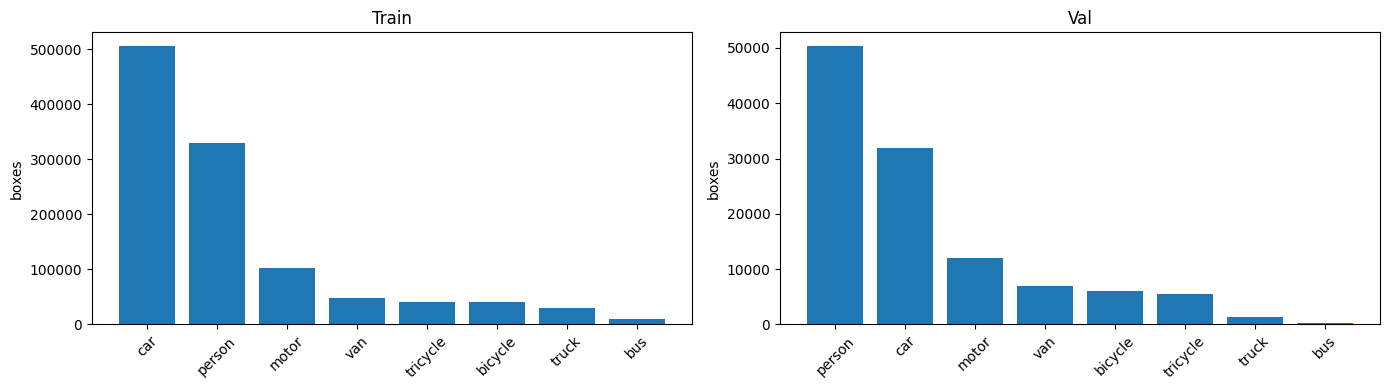

In [5]:
def class_counts(df):
    objects = df[df["kind"] == "object"].copy()
    objects["class_name"] = objects["class_id"].map(names)
    counts = (
        objects["class_name"]
        .value_counts()
        .rename_axis("class_name")
        .reset_index(name="boxes")
    )
    counts["share"] = counts["boxes"] / counts["boxes"].sum()
    return objects, counts

train_obj, train_counts = class_counts(train_df)
val_obj, val_counts = class_counts(val_df)
print("TRAIN")
print(train_counts.to_string(index=False))
print("\nVAL")
print(val_counts.to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, counts, title in (
    (axes[0], train_counts, "Train"),
    (axes[1], val_counts, "Val"),
):
    ax.bar(counts["class_name"], counts["boxes"])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("boxes")
fig.tight_layout()
plt.show()

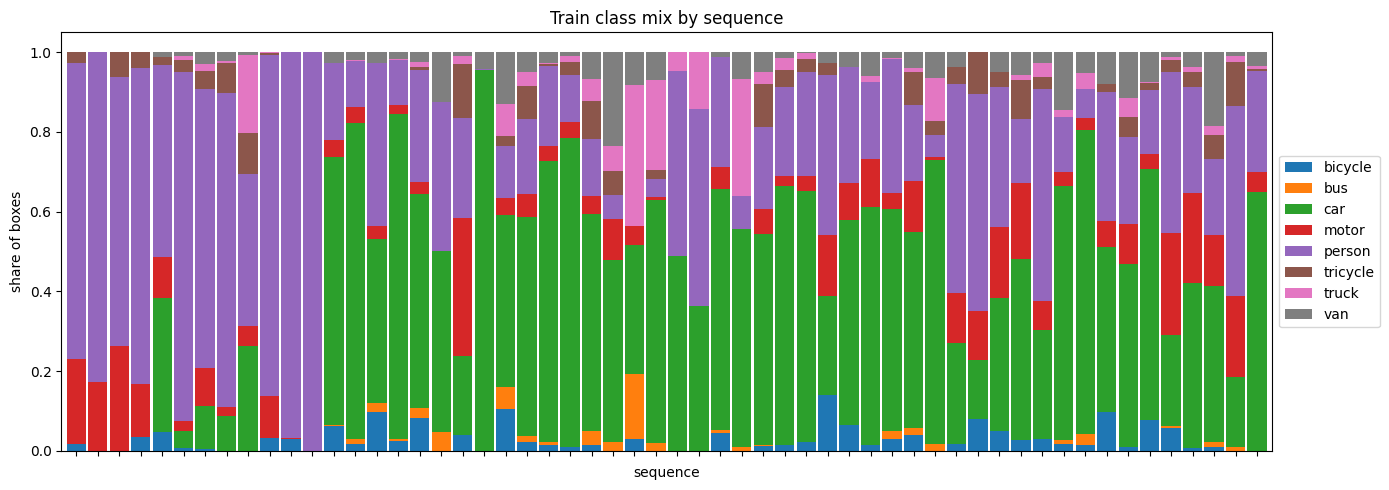

In [6]:
per_seq = (
    train_obj.groupby(["sequence", "class_name"])
    .size()
    .unstack(fill_value=0)
)
per_seq_share = per_seq.div(per_seq.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(14, 5))
per_seq_share.plot(kind="bar", stacked=True, ax=ax, width=0.9)
ax.set_title("Train class mix by sequence")
ax.set_ylabel("share of boxes")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_xticklabels([])
fig.tight_layout()
plt.show()

In [7]:
def with_pixel_size(df):
    objects = df[df["kind"] == "object"].copy()
    wh = {}
    for seq, path in objects.groupby("sequence")["image_path"].first().items():
        img = cv2.imread(path)
        wh[seq] = (img.shape[1], img.shape[0])
    objects["img_w"] = objects["sequence"].map(lambda s: wh[s][0])
    objects["img_h"] = objects["sequence"].map(lambda s: wh[s][1])
    objects["box_w"] = objects["w"] * objects["img_w"]
    objects["box_h"] = objects["h"] * objects["img_h"]
    objects["area"] = objects["box_w"] * objects["box_h"]
    return objects

def per_frame_counts(df):
    frames = df.drop_duplicates(["sequence", "frame"])[["sequence", "frame"]]
    counts = (
        df[df["kind"] == "object"]
        .groupby(["sequence", "frame"])
        .size()
        .rename("n_objects")
        .reset_index()
    )
    return frames.merge(counts, on=["sequence", "frame"], how="left").fillna({"n_objects": 0})

train_boxes = with_pixel_size(train_df)
val_boxes = with_pixel_size(val_df)
train_counts = per_frame_counts(train_df)
val_counts = per_frame_counts(val_df)


TRAIN
box width  px: median 44, p10 19, p90 126
box height px: median 48, p10 25, p90 97
COCO size bins: small 24.9%, medium 63.5%, large 11.6%
objects/frame: median 43, mean 45.7, max 180

VAL
box width  px: median 47, p10 20, p90 110
box height px: median 57, p10 29, p90 116
COCO size bins: small 19.2%, medium 69.5%, large 11.3%
objects/frame: median 37, mean 40.1, max 116


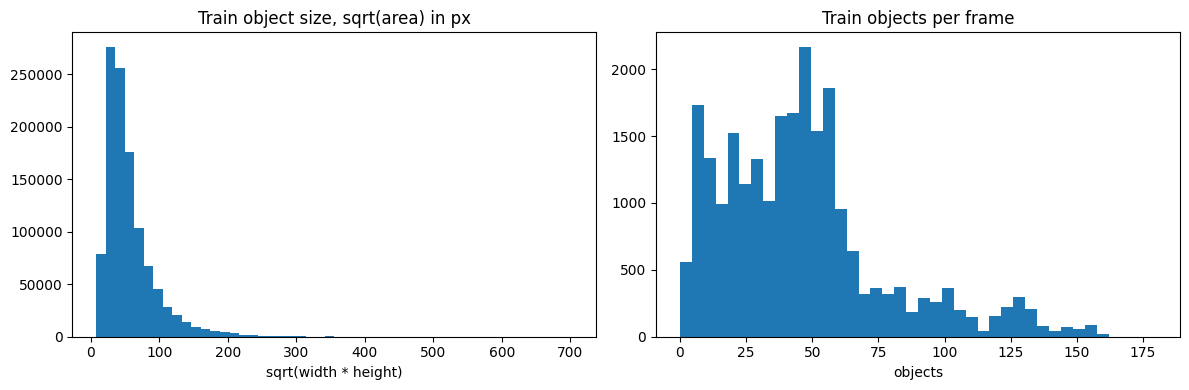

resolutions [(1344, 756), (1360, 765), (1904, 1071), (1920, 1080), (2688, 1512), (2720, 1530)]
aspect w/h p10, p50, p90: 0.44 0.95 2.13
dominant-class share within a sequence: min 34.6%, max 100.0%
densest sequences


,median,mean,max,median_area
sequence,,,,
uav0000138_00000_v,150.0,142.962441,156.0,2059.073456
uav0000126_00001_v,130.0,132.218447,166.0,2340.021696
uav0000124_00944_v,129.0,124.567839,134.0,2145.001127
uav0000072_04488_v,108.0,110.376471,124.0,2099.944350
uav0000150_02310_v,102.0,108.885057,174.0,3603.988592


sparsest sequences


,median,mean,max,median_area
sequence,,,,
uav0000099_02109_v,7.0,7.135458,13.0,1374.979820
uav0000266_03598_v,6.0,6.474453,10.0,6548.412416
uav0000263_03289_v,7.0,6.463448,11.0,3008.958639
uav0000266_04830_v,6.0,6.086207,7.0,6655.911424
uav0000218_00001_v,5.0,5.146667,7.0,3861.547948


In [8]:
def summarize(boxes, counts, title):
    print(f"\n{title}")
    print(f"box width  px: median {boxes.box_w.median():.0f}, p10 {boxes.box_w.quantile(.1):.0f}, p90 {boxes.box_w.quantile(.9):.0f}")
    print(f"box height px: median {boxes.box_h.median():.0f}, p10 {boxes.box_h.quantile(.1):.0f}, p90 {boxes.box_h.quantile(.9):.0f}")
    small = (boxes.area < 32 ** 2).mean()
    medium = ((boxes.area >= 32 ** 2) & (boxes.area < 96 ** 2)).mean()
    large = (boxes.area >= 96 ** 2).mean()
    print(f"COCO size bins: small {small:.1%}, medium {medium:.1%}, large {large:.1%}")
    print(f"objects/frame: median {counts.n_objects.median():.0f}, mean {counts.n_objects.mean():.1f}, max {counts.n_objects.max():.0f}")

summarize(train_boxes, train_counts, "TRAIN")
summarize(val_boxes, val_counts, "VAL")

test_per_clip = test_df.groupby("clip").size()
test_res = []
for path in test_df.groupby("clip")["image_path"].first():
    img = cv2.imread(path)
    test_res.append((img.shape[1], img.shape[0]))
print("\nTEST")
print(f"clips {test_df['clip'].nunique()}, frames {len(test_df)}")
print(
    f"frames/clip: median {test_per_clip.median():.0f}, "
    f"mean {test_per_clip.mean():.1f}, max {test_per_clip.max():.0f}"
)
print("resolutions", sorted(set(test_res)))
print("no boxes: test labels are not provided")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(np.sqrt(train_boxes.area), bins=50)
axes[0].set_title("Train object size, sqrt(area) in px")
axes[0].set_xlabel("sqrt(width * height)")
axes[1].hist(train_counts.n_objects, bins=40)
axes[1].set_title("Train objects per frame")
axes[1].set_xlabel("objects")
axes[2].hist(test_per_clip, bins=20)
axes[2].set_title("Test frames per clip")
axes[2].set_xlabel("frames")
fig.tight_layout()
plt.show()

by_seq = train_counts.groupby("sequence")["n_objects"].agg(["median", "mean", "max"])
by_seq["median_area"] = train_boxes.groupby("sequence")["area"].median()
by_seq = by_seq.sort_values("mean", ascending=False)

aspect = train_boxes.box_w / train_boxes.box_h.clip(lower=1)
dominant = per_seq_share.max(axis=1)
print("resolutions", sorted(set(zip(train_boxes.img_w.astype(int), train_boxes.img_h.astype(int)))))
print(
    "aspect w/h p10, p50, p90:",
    f"{aspect.quantile(0.1):.2f}",
    f"{aspect.median():.2f}",
    f"{aspect.quantile(0.9):.2f}",
)
print(
    "dominant-class share within a sequence: "
    f"min {dominant.min():.1%}, max {dominant.max():.1%}"
)
print("densest sequences")
display(by_seq.head(5))
print("sparsest sequences")
display(by_seq.tail(5))

Class mix, object size, and frame density belong to a whole video, not to a single frame.

**Classes.** Train boxes are 45.7% car, 29.7% person, 9.3% motor, then van 4.2%, tricycle 3.7%, bicycle 3.6%, truck 2.8%, and bus 0.9%. Val does not repeat that order: person is 44.1% and car is 27.9%, with motor 10.5%, van 6.0%, bicycle 5.3%, tricycle 4.8%, truck 1.2%, and bus 0.2%. The stacked bars are not flat across the 56 training videos, and the cell above prints how large a share the leading class takes inside a single sequence. One video is therefore a poor sample of the label set.

**Object size.** The median train box is 44×48 px (10th–90th percentile 19–126 px wide and 25–97 px tall). By COCO area bins, 24.9% are small (<32²), 63.5% are medium, and 11.6% are large. Val is similar but a bit taller: median 47×57 px, with 19.2% / 69.5% / 11.3%. Median box area still changes from sequence to sequence; the densest videos in the table above sit around 1–3k px². The same cell prints the width/height ratio at the 10th, 50th, and 90th percentiles and the distinct frame resolutions.

**Objects per frame.** Train frames hold a median of 43 objects (mean 45.7, max 180). Val is a little sparser: median 37, mean 40.1, max 116. The busiest training video, `uav0000138_00000_v`, averages 143 objects per frame. `uav0000295_02300_v` contains the frame with 180 objects. The sparsest videos are the tail of the same table.

**Test.** Test frames have no labels, so class mix and box size are not defined there. The cell above prints the number of clips, frames per clip, and the resolutions of those clips.

### Choices that follow from this

**Input resolution.** The training input is **1280** on the long side. A median box is only 44×48 px on the original frame, and a long side of 640 would shrink it by the same factor as the frame, often to well under 20 px.

**Anchors.** The size prior uses these widths, heights, and the printed aspect-ratio percentiles at the 1280 input. The spread covers compact people and wider vehicles, so one square prior does not fit the set.

**Augmentation.** Random scale is included because median object size changes across videos. Horizontal flip matches this UAV view. Train and validation stay split by sequence, because density and class mix belong to the whole video.


## Preprocessing

Labels are already YOLO text, one row per box: `class cx cy w h` with coordinates in `[0, 1]`. The loader converts each row to `cls, x1, y1, x2, y2` in pixels. A row with no class is an ignore region and is stored as class `-1`. Ignore boxes are drawn in yellow on the check below and are not training targets. The eight classes in `data.yaml` are the only targets. Other categories are already absent from `labels/`.

Train and validation are the sequence folders as provided. The next cell prints how many sequence names are shared. Frames from one video are highly correlated, so a frame-level split would leak the scene into the score. Test clips are not used for training.

Training keeps every 5th frame (`FRAME_STRIDE`). Neighboring frames of one clip are almost the same scene, so the step drops near-duplicates and does not move frames between videos.

Every split is letterboxed to 1280×1280. The aspect ratio stays as it is, and the empty border is filled with 114. The same scale and padding are applied to the boxes. Pixels then go through one `MinMaxScaler` fit on `[0, 255]`, which divides every pixel by 255. The scaler is not fit on the images. Train, validation, and test share this resize and this scaler.

Train-only augmentation uses `check_random_state(0)`: horizontal flip with probability 0.5, then a random scale in `[0.5, 1.5]`. Validation and test are letterbox and the scaler only. The figure checks one train frame, one val frame, and one test frame. Red boxes are labeled objects. The test frame has no labels.


In [9]:
train_seq = {p.name for p in (ROOT / "train/images").iterdir() if p.is_dir()}
val_seq = {p.name for p in (ROOT / "val/images").iterdir() if p.is_dir()}
print("train sequences", len(train_seq))
print("val sequences", len(val_seq))
print("shared sequences", len(train_seq & val_seq))

train sequences 56
val sequences 7
shared sequences 0


### Labels

In [ ]:
IMGSZ = 1280
SEED = 0
FRAME_STRIDE = 5

pixel_scaler = MinMaxScaler(feature_range=(0.0, 1.0))
pixel_scaler.fit(np.array([[0.0], [255.0]]))


def yolo_to_xyxy(label_path, width, height):
    # cls, x1, y1, x2, y2. A line with no class is an ignore region, stored as -1.
    rows = []
    label_path = Path(label_path)
    if not label_path.exists():
        return np.zeros((0, 5))
    for line in label_path.read_text().splitlines():
        vals = line.split()
        if len(vals) < 4:
            continue
        if len(vals) == 4:
            cls, cx, cy, bw, bh = -1.0, *map(float, vals)
        else:
            cls, cx, cy, bw, bh = map(float, vals[:5])
        rows.append([
            cls,
            (cx - bw / 2) * width, (cy - bh / 2) * height,
            (cx + bw / 2) * width, (cy + bh / 2) * height,
        ])
    return np.asarray(rows, dtype=np.float64) if rows else np.zeros((0, 5))

### Letterbox

In [ ]:
def letterbox(image, boxes, new_shape=IMGSZ):
    height, width = image.shape[:2]
    ratio = min(new_shape / height, new_shape / width)
    resized = cv2.resize(image, (int(round(width * ratio)), int(round(height * ratio))))
    canvas = np.full((new_shape, new_shape, 3), 114, dtype=np.uint8)
    top = (new_shape - resized.shape[0]) // 2
    left = (new_shape - resized.shape[1]) // 2
    canvas[top:top + resized.shape[0], left:left + resized.shape[1]] = resized
    out = boxes.copy()
    if len(out):
        out[:, [1, 3]] = out[:, [1, 3]] * ratio + left
        out[:, [2, 4]] = out[:, [2, 4]] * ratio + top
    return canvas, out


def normalize(image):
    flat = image.reshape(-1, 1).astype(np.float64)
    return pixel_scaler.transform(flat).reshape(image.shape).astype(np.float32)


def preprocess_val(image, boxes):
    boxed, boxed_boxes = letterbox(image, boxes)
    return normalize(boxed), boxed_boxes

### Augmentation

In [ ]:
def preprocess_train(image, boxes, rng):
    boxes = boxes.copy()
    if rng.rand() < 0.5:
        image = np.ascontiguousarray(np.fliplr(image))
        if len(boxes):
            x1 = image.shape[1] - boxes[:, 3]
            x2 = image.shape[1] - boxes[:, 1]
            boxes[:, 1] = np.minimum(x1, x2)
            boxes[:, 3] = np.maximum(x1, x2)
    factor = float(rng.uniform(0.5, 1.5))
    image = cv2.resize(
        image,
        (max(1, int(round(image.shape[1] * factor))), max(1, int(round(image.shape[0] * factor)))),
    )
    if len(boxes):
        boxes[:, 1:5] *= factor
    return preprocess_val(image, boxes)

### Check

In [ ]:
def paint(image, boxes, color):
    view = image.copy()
    for row in boxes:
        x1, y1, x2, y2 = row[1:].astype(int)
        cv2.rectangle(view, (x1, y1), (x2, y2), color, 2)
    return view


train_frames = sorted((ROOT / "train/images/uav0000138_00000_v").glob("*.jpg"))
val_dir = sorted(p for p in (ROOT / "val/images").iterdir() if p.is_dir())[0]
val_frames = sorted(val_dir.glob("*.jpg"))
test_path = Path(test_df["image_path"].iloc[len(test_df) // 2])


def load_frame(split, sequence, stem):
    image = cv2.cvtColor(
        cv2.imread(str(ROOT / split / "images" / sequence / f"{stem}.jpg")),
        cv2.COLOR_BGR2RGB,
    )
    height, width = image.shape[:2]
    objects = yolo_to_xyxy(ROOT / split / "labels" / sequence / f"{stem}.txt", width, height)
    ignored = yolo_to_xyxy(ROOT / split / "ignore" / sequence / f"{stem}.txt", width, height)
    return image, objects, ignored


panels = [
    (*load_frame("train", "uav0000138_00000_v", train_frames[len(train_frames) // 2].stem), "train"),
    (*load_frame("val", val_dir.name, val_frames[len(val_frames) // 2].stem), f"val/{val_dir.name}"),
]
test_image = cv2.cvtColor(cv2.imread(str(test_path)), cv2.COLOR_BGR2RGB)
panels.append((test_image, np.zeros((0, 5)), np.zeros((0, 5)), f"test/{test_path.parent.name}"))

fig, axes = plt.subplots(len(panels), 2, figsize=(12, 4 * len(panels)))
for ax, (image, objects, ignored, title) in zip(axes, panels):
    boxed, boxed_objects = letterbox(image, objects)
    _, boxed_ignored = letterbox(image, ignored)
    ax[0].imshow(paint(paint(image, objects, (255, 40, 40)), ignored, (255, 220, 0)))
    ax[0].set_title(f"{title}  objects={len(objects)}")
    ax[0].axis("off")
    ax[1].imshow(paint(paint(boxed, boxed_objects, (255, 40, 40)), boxed_ignored, (255, 220, 0)))
    ax[1].set_title(f"letterbox {IMGSZ}")
    ax[1].axis("off")
    norm = normalize(boxed)
    print(title, "normalized", float(norm.min()), float(norm.max()))
fig.tight_layout()
plt.show()
print("red = labeled objects, yellow = ignore. Test has no boxes.")